In [1]:
import numpy as np
import corner
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [5]:
lightcurves = pd.read_csv('imposter_gp_lightcurves.csv')

imposter2 = lightcurves[lightcurves["obj_id"] == 'ZTF22aajrrzz']

t_ref = imposter2['mjd'].tolist()
t_0 = imposter2['mjd_0'].tolist()
lum1 = imposter2['mag_ztfi'].to_numpy()
lum2 = imposter2['mag_ztfr'].to_numpy()
lum3 = imposter2['mag_ztfg'].to_numpy()

t_ref = np.array(t_ref)
t_0 = np.array(t_0)
lum1 = np.array(lum1)
lum2 = np.array(lum2)
lum3 = np.array(lum3)

t = t_ref - t_0

print(lum1)


[19.39281787 19.38105315 19.36940077 19.35785873 19.34642509 19.33509795
 19.32387548 19.31275591 19.30173751 19.29081859 19.27999753 19.26927274
 19.25864268 19.24810585 19.23766078 19.22730607 19.21704033 19.20686222
 19.19677043 19.18676369 19.17684075 19.16700042 19.1572415  19.14756287
 19.1379634  19.128442   19.11899762 19.10962921 19.10033577 19.09111632
 19.0819699  19.07289557 19.06389242 19.05495956 19.04609612 19.03730126
 19.02857413 19.01991394 19.01131989 19.00279122 18.99432717 18.98592701
 18.97759001 18.96931548 18.96110273 18.95295109 18.94485991 18.93682854
 18.92885635 18.92094275 18.91308712 18.90528889 18.89754748 18.88986233
 18.88223289 18.87465864 18.86713904 18.85967358 18.85226177 18.8449031
 18.83759711 18.83034332 18.82314128 18.81599052 18.80889061 18.80184113
 18.79484163 18.78789172 18.78099099 18.77413904 18.76733547 18.76057992
 18.75387201 18.74721136 18.74059763 18.73403047 18.72750952 18.72103445
 18.71460493 18.70822064 18.70188126 18.69558648 18.

In [6]:
def power_law(t, t_0, M):
    y_vals = M + 3.25 * np.log(t - t_0)
    return y_vals

In [7]:
init_guess = [np.min(t)-1, np.mean(lum1)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum1, pcov_lum1 = curve_fit(power_law, t, lum1, p0=init_guess, bounds=bounds)

-205.40317243879733
1.0089991679572812


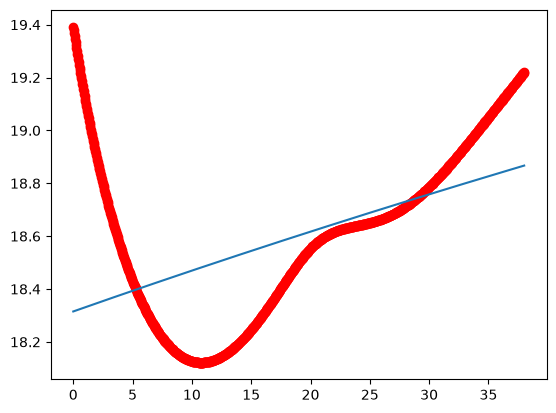

In [8]:
t_0_fit_lum1, M_fit_lum1 = popt_lum1

print(t_0_fit_lum1)
print(M_fit_lum1)

y_lum1 = power_law(t, t_0_fit_lum1, M_fit_lum1)

fig, axs = plt.subplots()
axs.scatter(t, lum1, color = 'r')
axs.plot(t, y_lum1)


In [9]:
init_guess = [np.min(t)-1, np.mean(lum2)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum2, pcov_lum2 = curve_fit(power_law, t, lum2, p0=init_guess, bounds=bounds)

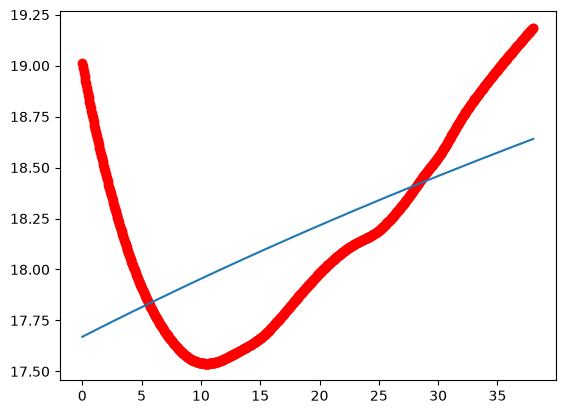

In [10]:
t_0_fit_lum2, M_fit_lum2 = popt_lum2

y_lum2 = power_law(t, t_0_fit_lum2, M_fit_lum2)

fig, axs = plt.subplots()
axs.scatter(t, lum2, color = 'r')
axs.plot(t, y_lum2)


In [11]:
init_guess = [np.min(t)-1, np.mean(lum3)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum3, pcov_lum3 = curve_fit(power_law, t, lum3, p0=init_guess, bounds=bounds)

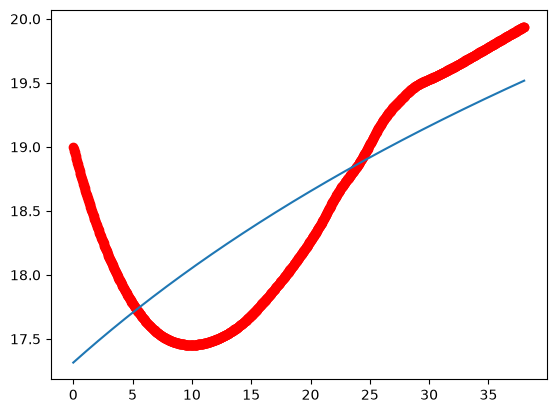

In [13]:
t_0_fit_lum3, M_fit_lum3 = popt_lum3

y_lum3 = power_law(t, t_0_fit_lum3, M_fit_lum3)

fig, axs = plt.subplots()
axs.scatter(t, lum3, color = 'r')
axs.plot(t, y_lum3)


In [14]:
class MetropolisHastings():

    def __init__(self):
        self.theta_chain = []

    def set_proposal_sigma(self, sigma):
        self.proposal_sigma = np.array(sigma)

    def set_target_distribution(self, function):
        self.target_distribution = function

    def initialize(self, theta_init, nsteps):
        self.theta_init = np.array(theta_init)
        self.nsteps = nsteps

    def sample(self):

        self.theta_chain = [self.theta_init.copy()]

        for i in range(self.nsteps):

            theta_prime = np.random.multivariate_normal(mean=self.theta_init, cov=np.diag(self.proposal_sigma**2))

            log_diff = (self.target_distribution(theta_prime) - self.target_distribution(self.theta_init))

            if np.log(np.random.uniform()) < min(0, log_diff):
                self.theta_init = theta_prime

            self.theta_chain.append(self.theta_init.copy())

        return np.array(self.theta_chain)

    def plot_corner(self):
        fig = corner.corner(np.array(self.theta_chain))
        return fig

In [16]:
lum1_err = imposter2['flux_error_ztfi'].to_numpy()
lum1_err = np.array(lum1_err)

In [17]:
def log_likelihood_lum1(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum1 - model) / lum1_err)**2+ np.log(2 * np.pi * lum1_err**2))

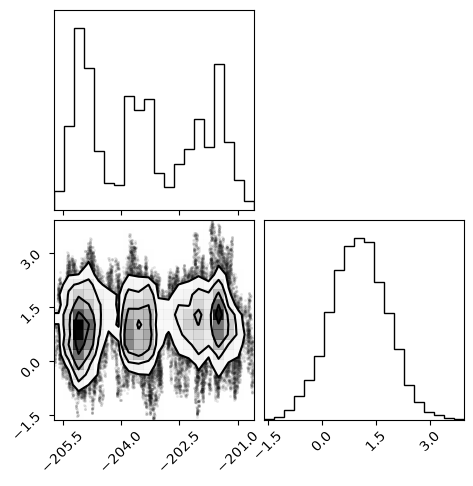

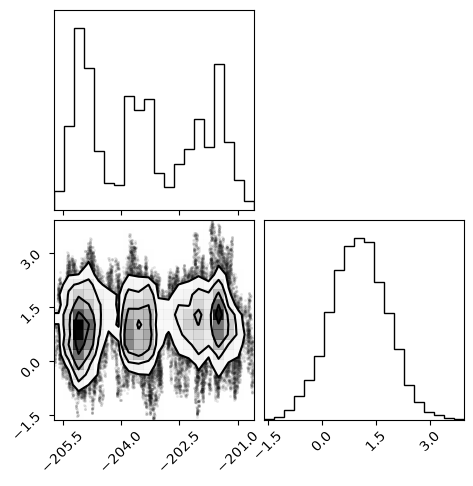

In [18]:
sampler = MetropolisHastings()

sampler.set_proposal_sigma([0.01, 0.1])

sampler.set_target_distribution(log_likelihood_lum1)

sampler.initialize(theta_init=[t_0_fit_lum1, M_fit_lum1], nsteps=100000)

samples = sampler.sample()

sampler.plot_corner()

In [19]:
lum2_err = imposter2['flux_error_ztfr'].to_numpy()
lum2_err = np.array(lum2_err)

In [20]:
def log_likelihood_lum2(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum2 - model) / lum2_err)**2+ np.log(2 * np.pi * lum2_err**2))

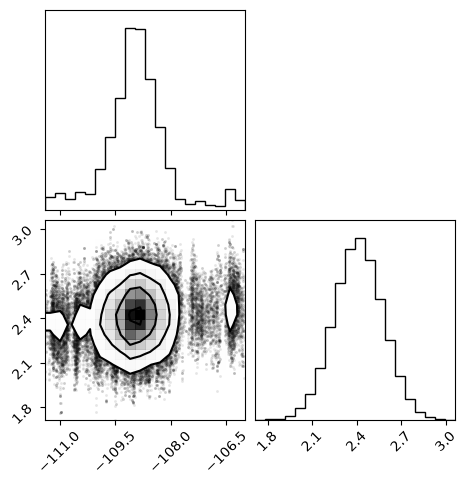

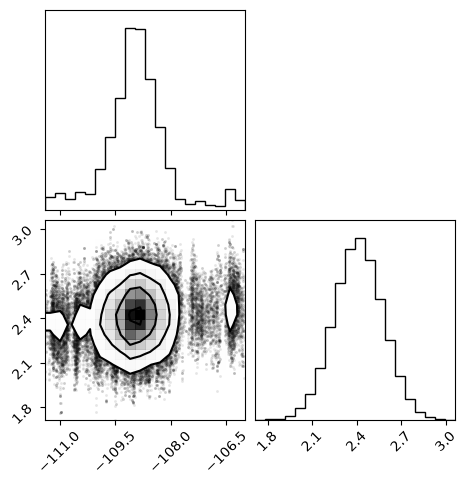

In [21]:
sampler2 = MetropolisHastings()

sampler2.set_proposal_sigma([0.01, 0.1])

sampler2.set_target_distribution(log_likelihood_lum2)

sampler2.initialize(theta_init=[t_0_fit_lum2, M_fit_lum2], nsteps=100000)

samples = sampler2.sample()

sampler2.plot_corner()

In [22]:
lum3_err = imposter2['flux_error_ztfg'].to_numpy()
lum3_err = np.array(lum3_err)

In [23]:
def log_likelihood_lum3(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum3 - model) / lum3_err)**2+ np.log(2 * np.pi * lum3_err**2))

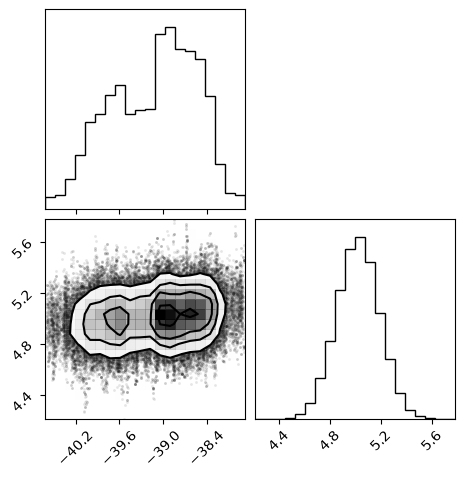

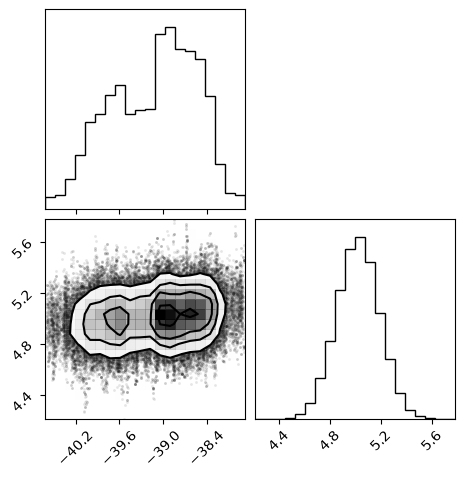

In [24]:
sampler3 = MetropolisHastings()

sampler3.set_proposal_sigma([0.01, 0.1])

sampler3.set_target_distribution(log_likelihood_lum2)

sampler3.initialize(theta_init=[t_0_fit_lum3, M_fit_lum3], nsteps=100000)

samples = sampler3.sample()

sampler3.plot_corner()

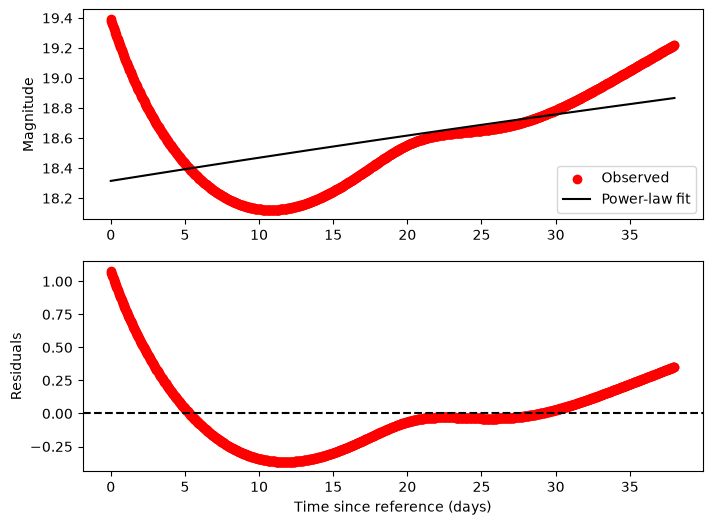

In [25]:
residuals_lum1 = lum1 - y_lum1

fig, axs = plt.subplots(2, 1, figsize=(8,6))

axs[0].scatter(t, lum1, color='r', label='Observed')
axs[0].plot(t, y_lum1, color='black', label='Power-law fit')
axs[0].set_ylabel('Magnitude')
axs[0].legend()

axs[1].scatter(t, residuals_lum1, color='r')
axs[1].axhline(0, color='black', linestyle='--')
axs[1].set_xlabel('Time since reference (days)')
axs[1].set_ylabel('Residuals')

plt.show()

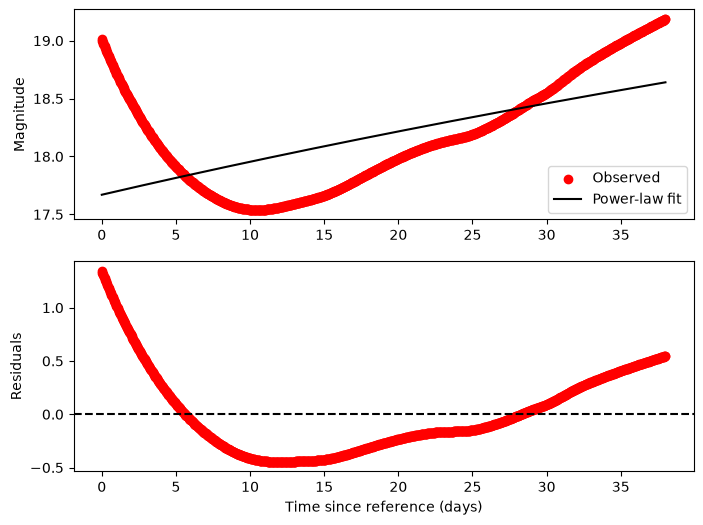

In [26]:
residuals_lum2 = lum2 - y_lum2

fig, axs = plt.subplots(2, 1, figsize=(8,6))

axs[0].scatter(t, lum2, color='r', label='Observed')
axs[0].plot(t, y_lum2, color='black', label='Power-law fit')
axs[0].set_ylabel('Magnitude')
axs[0].legend()

axs[1].scatter(t, residuals_lum2, color='r')
axs[1].axhline(0, color='black', linestyle='--')
axs[1].set_xlabel('Time since reference (days)')
axs[1].set_ylabel('Residuals')

plt.show()

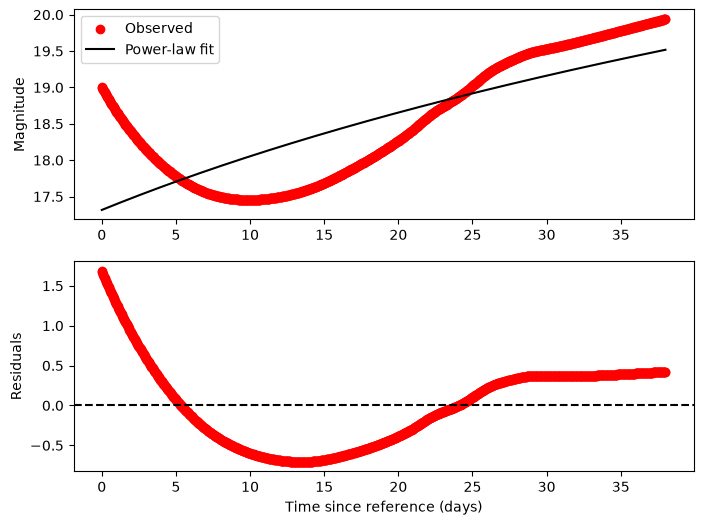

In [27]:
residuals_lum3 = lum3 - y_lum3

fig, axs = plt.subplots(2, 1, figsize=(8,6))

axs[0].scatter(t, lum3, color='r', label='Observed')
axs[0].plot(t, y_lum3, color='black', label='Power-law fit')
axs[0].set_ylabel('Magnitude')
axs[0].legend()

axs[1].scatter(t, residuals_lum3, color='r')
axs[1].axhline(0, color='black', linestyle='--')
axs[1].set_xlabel('Time since reference (days)')
axs[1].set_ylabel('Residuals')

plt.show()